In [389]:
import numpy as np
import pandas as pd

In [390]:
df = pd.read_csv("001_Farzad (2).csv", low_memory=False)
df

,Row,Timestamp,EventSource,SlideEvent,StimType,Duration,CollectionPhase,SourceStimuliName,EventSource.1,InputEventSource,...,Saccade Index,Saccade Index by Stimulus,Saccade Start,Saccade End,Saccade Duration,Saccade Amplitude,Saccade Peak Velocity,Saccade Peak Acceleration,Saccade Peak Deceleration,Saccade Direction
0,1,3.650740e+01,1.0,StartSlide,TestImage,3000000.0,StimuliDisplay,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,4.693490e+01,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,6.359570e+01,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,8.026610e+01,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,9.698610e+01,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
236416,236417,3.000456e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236417,236418,3.000460e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,Mouse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236418,236419,3.000473e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236419,236420,3.000475e+06,1.0,EndMedia,TestImage,3000000.0,StimuliDisplay,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [391]:
df['Event Label'].unique()

array([nan, 'Onset of warning sound', 'Risk response',
       'Not responded sound '], dtype=object)

In [392]:
df['Event Label'] = df['Event Label'].astype(str)

In [393]:


# Create a group number based on the 'onset of warning sound' to 'risk response' sequence
df['group'] = None  # Initialize group column

# Assign group numbers to the rows where the event label is 'onset of warning sound'
group_num = 0
group_in = True
for idx, row in df.iterrows():
    if row['Event Label'] == 'Onset of warning sound':
        group_num += 1  # New group for a new sequence
        group_in = True
    if row['Event Label'] in ['Risk response']:
        df.at[idx, 'group'] = group_num  # Assign group number to these rows
        group_in = False
    elif pd.isna(df.at[idx, 'group']) and group_in:
        df.at[idx, 'group'] = group_num  # For rows in between, assign the same group number
    else:
        df.at[idx, 'group'] = 0

df

,Row,Timestamp,EventSource,SlideEvent,StimType,Duration,CollectionPhase,SourceStimuliName,EventSource.1,InputEventSource,...,Saccade Index by Stimulus,Saccade Start,Saccade End,Saccade Duration,Saccade Amplitude,Saccade Peak Velocity,Saccade Peak Acceleration,Saccade Peak Deceleration,Saccade Direction,group
0,1,3.650740e+01,1.0,StartSlide,TestImage,3000000.0,StimuliDisplay,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2,4.693490e+01,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,3,6.359570e+01,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,4,8.026610e+01,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,5,9.698610e+01,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
236416,236417,3.000456e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
236417,236418,3.000460e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,Mouse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
236418,236419,3.000473e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
236419,236420,3.000475e+06,1.0,EndMedia,TestImage,3000000.0,StimuliDisplay,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


# windows_size

In [394]:
WINDOW_SIZE = 5000 #ms
df['Start_Time'] = df.groupby('group')['Timestamp'].transform('first')

# Filter the DataFrame to include only rows within the window size
df = df[
    (df['Timestamp'] >= df['Start_Time']) &
    (df['Timestamp'] <= df['Start_Time'] + WINDOW_SIZE)
    ]
df[df['group'] != 0]

,Row,Timestamp,EventSource,SlideEvent,StimType,Duration,CollectionPhase,SourceStimuliName,EventSource.1,InputEventSource,...,Saccade Start,Saccade End,Saccade Duration,Saccade Amplitude,Saccade Peak Velocity,Saccade Peak Acceleration,Saccade Peak Deceleration,Saccade Direction,group,Start_Time
9573,9574,1.239520e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
9574,9575,1.239554e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
9575,9576,1.239721e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
9576,9577,1.239836e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,Mouse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
9577,9578,1.239866e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,Keyboard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235915,235916,2.994939e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216
235916,235917,2.994956e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216
235917,235918,2.994973e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216
235918,235919,2.994989e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,2994981.024,2995031.029,50.0056,6.586753,197.278958,6189.753569,-4799.746386,200.919175,78,2994547.216


In [395]:
df = df[df['group'] != 0]


In [396]:
df

,Row,Timestamp,EventSource,SlideEvent,StimType,Duration,CollectionPhase,SourceStimuliName,EventSource.1,InputEventSource,...,Saccade Start,Saccade End,Saccade Duration,Saccade Amplitude,Saccade Peak Velocity,Saccade Peak Acceleration,Saccade Peak Deceleration,Saccade Direction,group,Start_Time
9573,9574,1.239520e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
9574,9575,1.239554e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
9575,9576,1.239721e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
9576,9577,1.239836e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,Mouse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
9577,9578,1.239866e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,Keyboard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235915,235916,2.994939e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216
235916,235917,2.994956e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216
235917,235918,2.994973e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216
235918,235919,2.994989e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,2994981.024,2995031.029,50.0056,6.586753,197.278958,6189.753569,-4799.746386,200.919175,78,2994547.216


In [397]:
# Method 2: More robust approach using first() and last() (handles single-row groups better)
response_times_robust = df.groupby('group')['Timestamp'].agg(first='first', last='last').assign(ResponseTime=lambda x: x['last'] - x['first']).reset_index()

df = pd.merge(df, response_times_robust[['group', 'ResponseTime']], on='group', how='left')

df


,Row,Timestamp,EventSource,SlideEvent,StimType,Duration,CollectionPhase,SourceStimuliName,EventSource.1,InputEventSource,...,Saccade End,Saccade Duration,Saccade Amplitude,Saccade Peak Velocity,Saccade Peak Acceleration,Saccade Peak Deceleration,Saccade Direction,group,Start_Time,ResponseTime
0,9574,1.239520e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045,1153.003
1,9575,1.239554e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045,1153.003
2,9576,1.239721e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045,1153.003
3,9577,1.239836e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,Mouse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045,1153.003
4,9578,1.239866e+05,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,Keyboard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,123952.045,1153.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11727,235916,2.994939e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216,450.330
11728,235917,2.994956e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216,450.330
11729,235918,2.994973e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78,2994547.216,450.330
11730,235919,2.994989e+06,NaN,NaN,NaN,NaN,NaN,Screen recording,NaN,NaN,...,2995031.029,50.0056,6.586753,197.278958,6189.753569,-4799.746386,200.919175,78,2994547.216,450.330


In [398]:
response_times_robust

,group,first,last,ResponseTime
0,1,123952.045,1.251050e+05,1153.0030
1,2,147746.240,1.486930e+05,946.7260
2,3,287340.050,2.879477e+05,607.6449
3,4,287950.231,2.883488e+05,398.6010
4,5,291967.918,2.962645e+05,4296.5769
...,...,...,...,...
73,74,2857701.022,2.859500e+06,1798.8730
74,75,2864203.797,2.869198e+06,4993.9890
75,76,2957336.936,2.957357e+06,19.7830
76,77,2969217.171,2.971355e+06,2137.5290


# windows_size

In [399]:
# already applied
# windows_size
# WINDOW_SIZE = 1000  #ms
# df['Start_Time'] = df.groupby('group')['Timestamp'].transform('first')
#
# # Filter the DataFrame to include only rows within the window size
# df = df[
#     (df['Timestamp'] >= df['Start_Time']) &
#     (df['Timestamp'] <= df['Start_Time'] + WINDOW_SIZE)
#     ]
# df[df['group'] != 0]

# Remove NaN

In [400]:
final_data = df[["group","Timestamp","Fixation Duration","ET_PupilLeft","ET_PupilRight","Gaze Velocity","Gaze Acceleration","ResponseTime"]]

final_data = final_data.dropna()
final_data

,group,Timestamp,Fixation Duration,ET_PupilLeft,ET_PupilRight,Gaze Velocity,Gaze Acceleration,ResponseTime
1,1,1.239554e+05,200.1032,3.300476,3.571590,25.617793,1361.831291,1153.003
2,1,1.239721e+05,200.1032,3.302517,3.574849,13.936440,-700.791482,1153.003
5,1,1.239888e+05,200.1032,3.303718,3.575371,22.546497,514.758486,1153.003
6,1,1.240054e+05,200.1032,3.307630,3.577801,12.008560,-634.082068,1153.003
8,1,1.240221e+05,200.1032,3.308602,3.580798,21.559071,573.012361,1153.003
...,...,...,...,...,...,...,...,...
11725,78,2.994906e+06,483.3640,3.766273,4.083576,3.011417,-87.034320,450.330
11726,78,2.994923e+06,483.3640,3.768609,4.085508,7.888158,292.623197,450.330
11727,78,2.994939e+06,483.3640,3.782112,4.097337,8.044017,9.348572,450.330
11728,78,2.994956e+06,483.3640,3.785028,4.098883,7.074656,-58.126339,450.330


# Selection feature

In [401]:
# Define custom aggregation functions for CV and IQR
def cv(series):
    return series.std() / series.mean()

def iqr(series):
    return series.quantile(0.75) - series.quantile(0.25)

def calculate_response_time(group):
    first_timestamp = group['Timestamp'].min()
    last_timestamp = group['Timestamp'].max()
    return last_timestamp - first_timestamp

In [402]:
final_data

,group,Timestamp,Fixation Duration,ET_PupilLeft,ET_PupilRight,Gaze Velocity,Gaze Acceleration,ResponseTime
1,1,1.239554e+05,200.1032,3.300476,3.571590,25.617793,1361.831291,1153.003
2,1,1.239721e+05,200.1032,3.302517,3.574849,13.936440,-700.791482,1153.003
5,1,1.239888e+05,200.1032,3.303718,3.575371,22.546497,514.758486,1153.003
6,1,1.240054e+05,200.1032,3.307630,3.577801,12.008560,-634.082068,1153.003
8,1,1.240221e+05,200.1032,3.308602,3.580798,21.559071,573.012361,1153.003
...,...,...,...,...,...,...,...,...
11725,78,2.994906e+06,483.3640,3.766273,4.083576,3.011417,-87.034320,450.330
11726,78,2.994923e+06,483.3640,3.768609,4.085508,7.888158,292.623197,450.330
11727,78,2.994939e+06,483.3640,3.782112,4.097337,8.044017,9.348572,450.330
11728,78,2.994956e+06,483.3640,3.785028,4.098883,7.074656,-58.126339,450.330


In [403]:
grouped_df = final_data.groupby('group').agg({
    'Gaze Velocity': ['min', 'max', 'mean', 'std', 'median', 'skew', 'std', cv,iqr],  # CV and IQR for Gaze Velocity
    'Gaze Acceleration': ['min', 'max', 'mean', 'std', 'median', 'skew', 'std', cv,iqr],  # CV and IQR for Gaze Acceleration
    'Fixation Duration': ['min', 'max', 'mean', 'std', 'median', 'skew', 'std', cv,iqr],  # CV and IQR for Fixation Duration
    'ET_PupilLeft': ['min', 'max', 'mean', 'std', 'median', 'skew', 'std', cv,iqr],  # CV and IQR for ET_PupilLeft
    'ET_PupilRight': ['min', 'max', 'mean', 'std', 'median', 'skew', 'std', cv,iqr],  # CV and IQR for ET_PupilRight
    'ResponseTime' : 'first'
})



In [404]:
grouped_df.columns = [' '.join(col).strip() for col in grouped_df.columns.values]


In [405]:
grouped_df

,Gaze Velocity min,Gaze Velocity max,Gaze Velocity mean,Gaze Velocity std,Gaze Velocity median,Gaze Velocity skew,Gaze Velocity std,Gaze Velocity cv,Gaze Velocity iqr,Gaze Acceleration min,...,ET_PupilRight min,ET_PupilRight max,ET_PupilRight mean,ET_PupilRight std,ET_PupilRight median,ET_PupilRight skew,ET_PupilRight std,ET_PupilRight cv,ET_PupilRight iqr,ResponseTime first
group,,,,,,,,,,,,,,,,,,,,,
1,0.790732,26.052198,11.820760,6.712800,10.791945,0.482271,6.712800,0.567882,10.161744,-6237.668387,...,3.571590,3.921628,3.708192,0.104247,3.683909,0.462029,0.104247,0.028113,0.181350,1153.0030
2,0.782130,22.363844,8.587881,4.597695,8.058950,0.687287,4.597695,0.535370,5.606834,-3283.758851,...,3.154394,3.347843,3.277044,0.075368,3.322790,-0.621219,0.075368,0.022999,0.154710,946.7260
3,1.918318,21.526620,10.845496,5.375320,9.497377,0.275251,5.375320,0.495627,7.441104,-5614.493007,...,3.281332,3.372236,3.310183,0.028565,3.300432,0.984898,0.028565,0.008629,0.038221,607.6449
4,3.049681,25.550728,11.622733,5.773980,11.829389,0.534722,5.773980,0.496783,7.065351,-2968.318697,...,3.372555,3.506078,3.423633,0.044954,3.418630,0.385808,0.044954,0.013130,0.076834,398.6010
5,0.353328,29.934670,11.791817,7.060852,10.859913,0.516895,7.060852,0.598793,11.218430,-8378.911059,...,3.299398,3.450938,3.405349,0.029434,3.410101,-1.528084,0.029434,0.008644,0.035013,4296.5769
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,0.333804,28.745366,11.194743,6.861302,10.692716,0.489576,6.861302,0.612904,9.684659,-5202.456322,...,3.841551,3.997080,3.924968,0.044555,3.924273,-0.172343,0.044555,0.011352,0.058335,1798.8730
75,0.454524,41.673854,11.658238,7.436669,10.285116,0.996996,7.436669,0.637890,9.273365,-7937.522492,...,3.603414,4.611985,4.273507,0.290023,4.370123,-0.774877,0.290023,0.067865,0.439101,4993.9890
76,11.623068,11.623068,11.623068,NaN,11.623068,NaN,NaN,NaN,0.000000,578.853256,...,3.460114,3.460114,3.460114,NaN,3.460114,NaN,NaN,NaN,0.000000,19.7830


In [406]:
grouped_df

,Gaze Velocity min,Gaze Velocity max,Gaze Velocity mean,Gaze Velocity std,Gaze Velocity median,Gaze Velocity skew,Gaze Velocity std,Gaze Velocity cv,Gaze Velocity iqr,Gaze Acceleration min,...,ET_PupilRight min,ET_PupilRight max,ET_PupilRight mean,ET_PupilRight std,ET_PupilRight median,ET_PupilRight skew,ET_PupilRight std,ET_PupilRight cv,ET_PupilRight iqr,ResponseTime first
group,,,,,,,,,,,,,,,,,,,,,
1,0.790732,26.052198,11.820760,6.712800,10.791945,0.482271,6.712800,0.567882,10.161744,-6237.668387,...,3.571590,3.921628,3.708192,0.104247,3.683909,0.462029,0.104247,0.028113,0.181350,1153.0030
2,0.782130,22.363844,8.587881,4.597695,8.058950,0.687287,4.597695,0.535370,5.606834,-3283.758851,...,3.154394,3.347843,3.277044,0.075368,3.322790,-0.621219,0.075368,0.022999,0.154710,946.7260
3,1.918318,21.526620,10.845496,5.375320,9.497377,0.275251,5.375320,0.495627,7.441104,-5614.493007,...,3.281332,3.372236,3.310183,0.028565,3.300432,0.984898,0.028565,0.008629,0.038221,607.6449
4,3.049681,25.550728,11.622733,5.773980,11.829389,0.534722,5.773980,0.496783,7.065351,-2968.318697,...,3.372555,3.506078,3.423633,0.044954,3.418630,0.385808,0.044954,0.013130,0.076834,398.6010
5,0.353328,29.934670,11.791817,7.060852,10.859913,0.516895,7.060852,0.598793,11.218430,-8378.911059,...,3.299398,3.450938,3.405349,0.029434,3.410101,-1.528084,0.029434,0.008644,0.035013,4296.5769
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,0.333804,28.745366,11.194743,6.861302,10.692716,0.489576,6.861302,0.612904,9.684659,-5202.456322,...,3.841551,3.997080,3.924968,0.044555,3.924273,-0.172343,0.044555,0.011352,0.058335,1798.8730
75,0.454524,41.673854,11.658238,7.436669,10.285116,0.996996,7.436669,0.637890,9.273365,-7937.522492,...,3.603414,4.611985,4.273507,0.290023,4.370123,-0.774877,0.290023,0.067865,0.439101,4993.9890
76,11.623068,11.623068,11.623068,NaN,11.623068,NaN,NaN,NaN,0.000000,578.853256,...,3.460114,3.460114,3.460114,NaN,3.460114,NaN,NaN,NaN,0.000000,19.7830


In [407]:
grouped_df.isnull().sum()

Gaze Velocity min           0
Gaze Velocity max           0
Gaze Velocity mean          0
Gaze Velocity std           2
Gaze Velocity median        0
Gaze Velocity skew          2
Gaze Velocity std           2
Gaze Velocity cv            2
Gaze Velocity iqr           0
Gaze Acceleration min       0
Gaze Acceleration max       0
Gaze Acceleration mean      0
Gaze Acceleration std       2
Gaze Acceleration median    0
Gaze Acceleration skew      2
Gaze Acceleration std       2
Gaze Acceleration cv        2
Gaze Acceleration iqr       0
Fixation Duration min       0
Fixation Duration max       0
Fixation Duration mean      0
Fixation Duration std       2
Fixation Duration median    0
Fixation Duration skew      2
Fixation Duration std       2
Fixation Duration cv        2
Fixation Duration iqr       0
ET_PupilLeft min            0
ET_PupilLeft max            0
ET_PupilLeft mean           0
ET_PupilLeft std            2
ET_PupilLeft median         0
ET_PupilLeft skew           2
ET_PupilLe

In [408]:
grouped_df =  grouped_df.dropna()
grouped_df.isnull().sum()


Gaze Velocity min           0
Gaze Velocity max           0
Gaze Velocity mean          0
Gaze Velocity std           0
Gaze Velocity median        0
Gaze Velocity skew          0
Gaze Velocity std           0
Gaze Velocity cv            0
Gaze Velocity iqr           0
Gaze Acceleration min       0
Gaze Acceleration max       0
Gaze Acceleration mean      0
Gaze Acceleration std       0
Gaze Acceleration median    0
Gaze Acceleration skew      0
Gaze Acceleration std       0
Gaze Acceleration cv        0
Gaze Acceleration iqr       0
Fixation Duration min       0
Fixation Duration max       0
Fixation Duration mean      0
Fixation Duration std       0
Fixation Duration median    0
Fixation Duration skew      0
Fixation Duration std       0
Fixation Duration cv        0
Fixation Duration iqr       0
ET_PupilLeft min            0
ET_PupilLeft max            0
ET_PupilLeft mean           0
ET_PupilLeft std            0
ET_PupilLeft median         0
ET_PupilLeft skew           0
ET_PupilLe

In [409]:
grouped_df

,Gaze Velocity min,Gaze Velocity max,Gaze Velocity mean,Gaze Velocity std,Gaze Velocity median,Gaze Velocity skew,Gaze Velocity std,Gaze Velocity cv,Gaze Velocity iqr,Gaze Acceleration min,...,ET_PupilRight min,ET_PupilRight max,ET_PupilRight mean,ET_PupilRight std,ET_PupilRight median,ET_PupilRight skew,ET_PupilRight std,ET_PupilRight cv,ET_PupilRight iqr,ResponseTime first
group,,,,,,,,,,,,,,,,,,,,,
1,0.790732,26.052198,11.820760,6.712800,10.791945,0.482271,6.712800,0.567882,10.161744,-6237.668387,...,3.571590,3.921628,3.708192,0.104247,3.683909,0.462029,0.104247,0.028113,0.181350,1153.0030
2,0.782130,22.363844,8.587881,4.597695,8.058950,0.687287,4.597695,0.535370,5.606834,-3283.758851,...,3.154394,3.347843,3.277044,0.075368,3.322790,-0.621219,0.075368,0.022999,0.154710,946.7260
3,1.918318,21.526620,10.845496,5.375320,9.497377,0.275251,5.375320,0.495627,7.441104,-5614.493007,...,3.281332,3.372236,3.310183,0.028565,3.300432,0.984898,0.028565,0.008629,0.038221,607.6449
4,3.049681,25.550728,11.622733,5.773980,11.829389,0.534722,5.773980,0.496783,7.065351,-2968.318697,...,3.372555,3.506078,3.423633,0.044954,3.418630,0.385808,0.044954,0.013130,0.076834,398.6010
5,0.353328,29.934670,11.791817,7.060852,10.859913,0.516895,7.060852,0.598793,11.218430,-8378.911059,...,3.299398,3.450938,3.405349,0.029434,3.410101,-1.528084,0.029434,0.008644,0.035013,4296.5769
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,1.064127,16.910445,9.421829,4.691026,9.169273,-0.200063,4.691026,0.497889,3.586152,-950.748619,...,3.872995,3.885174,3.878296,0.004044,3.878319,0.283452,0.004044,0.001043,0.004149,125.4430
74,0.333804,28.745366,11.194743,6.861302,10.692716,0.489576,6.861302,0.612904,9.684659,-5202.456322,...,3.841551,3.997080,3.924968,0.044555,3.924273,-0.172343,0.044555,0.011352,0.058335,1798.8730
75,0.454524,41.673854,11.658238,7.436669,10.285116,0.996996,7.436669,0.637890,9.273365,-7937.522492,...,3.603414,4.611985,4.273507,0.290023,4.370123,-0.774877,0.290023,0.067865,0.439101,4993.9890


In [410]:
grouped_df.columns

Index(['Gaze Velocity min', 'Gaze Velocity max', 'Gaze Velocity mean',
       'Gaze Velocity std', 'Gaze Velocity median', 'Gaze Velocity skew',
       'Gaze Velocity std', 'Gaze Velocity cv', 'Gaze Velocity iqr',
       'Gaze Acceleration min', 'Gaze Acceleration max',
       'Gaze Acceleration mean', 'Gaze Acceleration std',
       'Gaze Acceleration median', 'Gaze Acceleration skew',
       'Gaze Acceleration std', 'Gaze Acceleration cv',
       'Gaze Acceleration iqr', 'Fixation Duration min',
       'Fixation Duration max', 'Fixation Duration mean',
       'Fixation Duration std', 'Fixation Duration median',
       'Fixation Duration skew', 'Fixation Duration std',
       'Fixation Duration cv', 'Fixation Duration iqr', 'ET_PupilLeft min',
       'ET_PupilLeft max', 'ET_PupilLeft mean', 'ET_PupilLeft std',
       'ET_PupilLeft median', 'ET_PupilLeft skew', 'ET_PupilLeft std',
       'ET_PupilLeft cv', 'ET_PupilLeft iqr', 'ET_PupilRight min',
       'ET_PupilRight max', 'ET_PupilRi

In [411]:
grouped_df = grouped_df.rename(columns={'ResponseTime first': 'Response Time'})
grouped_df

,Gaze Velocity min,Gaze Velocity max,Gaze Velocity mean,Gaze Velocity std,Gaze Velocity median,Gaze Velocity skew,Gaze Velocity std,Gaze Velocity cv,Gaze Velocity iqr,Gaze Acceleration min,...,ET_PupilRight min,ET_PupilRight max,ET_PupilRight mean,ET_PupilRight std,ET_PupilRight median,ET_PupilRight skew,ET_PupilRight std,ET_PupilRight cv,ET_PupilRight iqr,Response Time
group,,,,,,,,,,,,,,,,,,,,,
1,0.790732,26.052198,11.820760,6.712800,10.791945,0.482271,6.712800,0.567882,10.161744,-6237.668387,...,3.571590,3.921628,3.708192,0.104247,3.683909,0.462029,0.104247,0.028113,0.181350,1153.0030
2,0.782130,22.363844,8.587881,4.597695,8.058950,0.687287,4.597695,0.535370,5.606834,-3283.758851,...,3.154394,3.347843,3.277044,0.075368,3.322790,-0.621219,0.075368,0.022999,0.154710,946.7260
3,1.918318,21.526620,10.845496,5.375320,9.497377,0.275251,5.375320,0.495627,7.441104,-5614.493007,...,3.281332,3.372236,3.310183,0.028565,3.300432,0.984898,0.028565,0.008629,0.038221,607.6449
4,3.049681,25.550728,11.622733,5.773980,11.829389,0.534722,5.773980,0.496783,7.065351,-2968.318697,...,3.372555,3.506078,3.423633,0.044954,3.418630,0.385808,0.044954,0.013130,0.076834,398.6010
5,0.353328,29.934670,11.791817,7.060852,10.859913,0.516895,7.060852,0.598793,11.218430,-8378.911059,...,3.299398,3.450938,3.405349,0.029434,3.410101,-1.528084,0.029434,0.008644,0.035013,4296.5769
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,1.064127,16.910445,9.421829,4.691026,9.169273,-0.200063,4.691026,0.497889,3.586152,-950.748619,...,3.872995,3.885174,3.878296,0.004044,3.878319,0.283452,0.004044,0.001043,0.004149,125.4430
74,0.333804,28.745366,11.194743,6.861302,10.692716,0.489576,6.861302,0.612904,9.684659,-5202.456322,...,3.841551,3.997080,3.924968,0.044555,3.924273,-0.172343,0.044555,0.011352,0.058335,1798.8730
75,0.454524,41.673854,11.658238,7.436669,10.285116,0.996996,7.436669,0.637890,9.273365,-7937.522492,...,3.603414,4.611985,4.273507,0.290023,4.370123,-0.774877,0.290023,0.067865,0.439101,4993.9890


# Data is ready for train

In [412]:
grouped_df.columns

Index(['Gaze Velocity min', 'Gaze Velocity max', 'Gaze Velocity mean',
       'Gaze Velocity std', 'Gaze Velocity median', 'Gaze Velocity skew',
       'Gaze Velocity std', 'Gaze Velocity cv', 'Gaze Velocity iqr',
       'Gaze Acceleration min', 'Gaze Acceleration max',
       'Gaze Acceleration mean', 'Gaze Acceleration std',
       'Gaze Acceleration median', 'Gaze Acceleration skew',
       'Gaze Acceleration std', 'Gaze Acceleration cv',
       'Gaze Acceleration iqr', 'Fixation Duration min',
       'Fixation Duration max', 'Fixation Duration mean',
       'Fixation Duration std', 'Fixation Duration median',
       'Fixation Duration skew', 'Fixation Duration std',
       'Fixation Duration cv', 'Fixation Duration iqr', 'ET_PupilLeft min',
       'ET_PupilLeft max', 'ET_PupilLeft mean', 'ET_PupilLeft std',
       'ET_PupilLeft median', 'ET_PupilLeft skew', 'ET_PupilLeft std',
       'ET_PupilLeft cv', 'ET_PupilLeft iqr', 'ET_PupilRight min',
       'ET_PupilRight max', 'ET_PupilRi

# Outlier

In [414]:

grouped_df.loc[:, 'Response Time'] = grouped_df['Response Time'] / 1000
# Remove rows where 'Response Time' is greater than 2000
# grouped_df = grouped_df[grouped_df['Response Time'] <= 5]


In [415]:
grouped_df

,Gaze Velocity min,Gaze Velocity max,Gaze Velocity mean,Gaze Velocity std,Gaze Velocity median,Gaze Velocity skew,Gaze Velocity std,Gaze Velocity cv,Gaze Velocity iqr,Gaze Acceleration min,...,ET_PupilRight min,ET_PupilRight max,ET_PupilRight mean,ET_PupilRight std,ET_PupilRight median,ET_PupilRight skew,ET_PupilRight std,ET_PupilRight cv,ET_PupilRight iqr,Response Time
group,,,,,,,,,,,,,,,,,,,,,
1,0.790732,26.052198,11.820760,6.712800,10.791945,0.482271,6.712800,0.567882,10.161744,-6237.668387,...,3.571590,3.921628,3.708192,0.104247,3.683909,0.462029,0.104247,0.028113,0.181350,1.153003
2,0.782130,22.363844,8.587881,4.597695,8.058950,0.687287,4.597695,0.535370,5.606834,-3283.758851,...,3.154394,3.347843,3.277044,0.075368,3.322790,-0.621219,0.075368,0.022999,0.154710,0.946726
3,1.918318,21.526620,10.845496,5.375320,9.497377,0.275251,5.375320,0.495627,7.441104,-5614.493007,...,3.281332,3.372236,3.310183,0.028565,3.300432,0.984898,0.028565,0.008629,0.038221,0.607645
4,3.049681,25.550728,11.622733,5.773980,11.829389,0.534722,5.773980,0.496783,7.065351,-2968.318697,...,3.372555,3.506078,3.423633,0.044954,3.418630,0.385808,0.044954,0.013130,0.076834,0.398601
5,0.353328,29.934670,11.791817,7.060852,10.859913,0.516895,7.060852,0.598793,11.218430,-8378.911059,...,3.299398,3.450938,3.405349,0.029434,3.410101,-1.528084,0.029434,0.008644,0.035013,4.296577
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,1.064127,16.910445,9.421829,4.691026,9.169273,-0.200063,4.691026,0.497889,3.586152,-950.748619,...,3.872995,3.885174,3.878296,0.004044,3.878319,0.283452,0.004044,0.001043,0.004149,0.125443
74,0.333804,28.745366,11.194743,6.861302,10.692716,0.489576,6.861302,0.612904,9.684659,-5202.456322,...,3.841551,3.997080,3.924968,0.044555,3.924273,-0.172343,0.044555,0.011352,0.058335,1.798873
75,0.454524,41.673854,11.658238,7.436669,10.285116,0.996996,7.436669,0.637890,9.273365,-7937.522492,...,3.603414,4.611985,4.273507,0.290023,4.370123,-0.774877,0.290023,0.067865,0.439101,4.993989


In [416]:
# Define the bin edges based on the response time thresholds
bins = [0, 1, 3, 6, np.inf]  # 0-1, 1-3, 3-6, 6+
labels = [1, 2, 3, 4]  # Labels for each bin

# Create the 'Response Time Classified' column using pd.cut
# grouped_df['Response Time Classified'] = pd.cut(grouped_df['Response Time'], bins=bins, labels=labels, right=False)
# Use .loc[] to avoid SettingWithCopyWarning
grouped_df.loc[:, 'Response Time Classified'] = pd.cut(grouped_df['Response Time'], bins=bins, labels=labels, right=False)
grouped_df

,Gaze Velocity min,Gaze Velocity max,Gaze Velocity mean,Gaze Velocity std,Gaze Velocity median,Gaze Velocity skew,Gaze Velocity std,Gaze Velocity cv,Gaze Velocity iqr,Gaze Acceleration min,...,ET_PupilRight max,ET_PupilRight mean,ET_PupilRight std,ET_PupilRight median,ET_PupilRight skew,ET_PupilRight std,ET_PupilRight cv,ET_PupilRight iqr,Response Time,Response Time Classified
group,,,,,,,,,,,,,,,,,,,,,
1,0.790732,26.052198,11.820760,6.712800,10.791945,0.482271,6.712800,0.567882,10.161744,-6237.668387,...,3.921628,3.708192,0.104247,3.683909,0.462029,0.104247,0.028113,0.181350,1.153003,2
2,0.782130,22.363844,8.587881,4.597695,8.058950,0.687287,4.597695,0.535370,5.606834,-3283.758851,...,3.347843,3.277044,0.075368,3.322790,-0.621219,0.075368,0.022999,0.154710,0.946726,1
3,1.918318,21.526620,10.845496,5.375320,9.497377,0.275251,5.375320,0.495627,7.441104,-5614.493007,...,3.372236,3.310183,0.028565,3.300432,0.984898,0.028565,0.008629,0.038221,0.607645,1
4,3.049681,25.550728,11.622733,5.773980,11.829389,0.534722,5.773980,0.496783,7.065351,-2968.318697,...,3.506078,3.423633,0.044954,3.418630,0.385808,0.044954,0.013130,0.076834,0.398601,1
5,0.353328,29.934670,11.791817,7.060852,10.859913,0.516895,7.060852,0.598793,11.218430,-8378.911059,...,3.450938,3.405349,0.029434,3.410101,-1.528084,0.029434,0.008644,0.035013,4.296577,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,1.064127,16.910445,9.421829,4.691026,9.169273,-0.200063,4.691026,0.497889,3.586152,-950.748619,...,3.885174,3.878296,0.004044,3.878319,0.283452,0.004044,0.001043,0.004149,0.125443,1
74,0.333804,28.745366,11.194743,6.861302,10.692716,0.489576,6.861302,0.612904,9.684659,-5202.456322,...,3.997080,3.924968,0.044555,3.924273,-0.172343,0.044555,0.011352,0.058335,1.798873,2
75,0.454524,41.673854,11.658238,7.436669,10.285116,0.996996,7.436669,0.637890,9.273365,-7937.522492,...,4.611985,4.273507,0.290023,4.370123,-0.774877,0.290023,0.067865,0.439101,4.993989,3


In [417]:
X = grouped_df.drop(columns=['Response Time','Response Time Classified'])  # Exclude the columns you don't want to use
y = grouped_df['Response Time']  # Assuming 'response time' is the target variable
# y = grouped_df['Response Time Classified']  # Assuming 'response time' is the target variable
y

group
1     1.153003
2     0.946726
3     0.607645
4     0.398601
5     4.296577
        ...   
73    0.125443
74    1.798873
75    4.993989
77    2.137529
78    0.450330
Name: Response Time, Length: 74, dtype: float64

In [418]:
X

,Gaze Velocity min,Gaze Velocity max,Gaze Velocity mean,Gaze Velocity std,Gaze Velocity median,Gaze Velocity skew,Gaze Velocity std,Gaze Velocity cv,Gaze Velocity iqr,Gaze Acceleration min,...,ET_PupilLeft iqr,ET_PupilRight min,ET_PupilRight max,ET_PupilRight mean,ET_PupilRight std,ET_PupilRight median,ET_PupilRight skew,ET_PupilRight std,ET_PupilRight cv,ET_PupilRight iqr
group,,,,,,,,,,,,,,,,,,,,,
1,0.790732,26.052198,11.820760,6.712800,10.791945,0.482271,6.712800,0.567882,10.161744,-6237.668387,...,0.087551,3.571590,3.921628,3.708192,0.104247,3.683909,0.462029,0.104247,0.028113,0.181350
2,0.782130,22.363844,8.587881,4.597695,8.058950,0.687287,4.597695,0.535370,5.606834,-3283.758851,...,0.191924,3.154394,3.347843,3.277044,0.075368,3.322790,-0.621219,0.075368,0.022999,0.154710
3,1.918318,21.526620,10.845496,5.375320,9.497377,0.275251,5.375320,0.495627,7.441104,-5614.493007,...,0.007012,3.281332,3.372236,3.310183,0.028565,3.300432,0.984898,0.028565,0.008629,0.038221
4,3.049681,25.550728,11.622733,5.773980,11.829389,0.534722,5.773980,0.496783,7.065351,-2968.318697,...,0.118028,3.372555,3.506078,3.423633,0.044954,3.418630,0.385808,0.044954,0.013130,0.076834
5,0.353328,29.934670,11.791817,7.060852,10.859913,0.516895,7.060852,0.598793,11.218430,-8378.911059,...,0.041928,3.299398,3.450938,3.405349,0.029434,3.410101,-1.528084,0.029434,0.008644,0.035013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,1.064127,16.910445,9.421829,4.691026,9.169273,-0.200063,4.691026,0.497889,3.586152,-950.748619,...,0.007010,3.872995,3.885174,3.878296,0.004044,3.878319,0.283452,0.004044,0.001043,0.004149
74,0.333804,28.745366,11.194743,6.861302,10.692716,0.489576,6.861302,0.612904,9.684659,-5202.456322,...,0.074630,3.841551,3.997080,3.924968,0.044555,3.924273,-0.172343,0.044555,0.011352,0.058335
75,0.454524,41.673854,11.658238,7.436669,10.285116,0.996996,7.436669,0.637890,9.273365,-7937.522492,...,0.409487,3.603414,4.611985,4.273507,0.290023,4.370123,-0.774877,0.290023,0.067865,0.439101


# Label statistics

In [419]:
# Descriptive statistics
stats = y.describe()
print(stats)
# Additional measures
mean = y.mean()
std_dev = y.std()
variance = y.var()
median = y.median()
skewness = y.skew()
kurtosis = y.kurtosis()

# Quantiles
q1 = np.percentile(y, 25)  # 25th percentile
q3 = np.percentile(y, 75)  # 75th percentile
iqr = q3 - q1  # Interquartile Range

# Outlier detection (using IQR method)
# lower_bound = q1 - 1.5 * iqr
# upper_bound = q3 + 1.5 * iqr
# outliers = y[(y < lower_bound) | (y > upper_bound)]

# Print all the statistics
print("Descriptive Statistics:\n", stats)
print("\nAdditional Measures:")
print(f"Mean: {mean:.4f}")
print(f"Standard Deviation: {std_dev:.4f}")
print(f"Variance: {variance:.4f}")
print(f"Median: {median:.4f}")
print(f"Skewness: {skewness:.4f}")
print(f"Kurtosis: {kurtosis:.4f}")
print(f"Interquartile Range (IQR): {iqr:.4f}")
# print(f"Outliers (if any):\n{outliers}")

count    74.000000
mean      1.996201
std       1.804330
min       0.070111
25%       0.513937
50%       1.194388
75%       3.571767
max       4.999549
Name: Response Time, dtype: float64
Descriptive Statistics:
 count    74.000000
mean      1.996201
std       1.804330
min       0.070111
25%       0.513937
50%       1.194388
75%       3.571767
max       4.999549
Name: Response Time, dtype: float64

Additional Measures:
Mean: 1.9962
Standard Deviation: 1.8043
Variance: 3.2556
Median: 1.1944
Skewness: 0.7669
Kurtosis: -1.0552
Interquartile Range (IQR): 3.0578


# Gussian SVM

In [420]:
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize KFold
kf = KFold(n_splits=5, shuffle=False)  # 5-fold cross-validation, change as needed

# Lists to store the performance metrics across folds
mse_scores = []
mae_scores = []
r2_scores = []

# Define the parameter grid for GridSearchCV
param_grid = {'C': [0.1, 1, 10], 'epsilon': [0.01, 0.1, 0.5], 'gamma': ['scale', 'auto']}

# K-fold cross-validation
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and test sets
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Initialize the GridSearchCV with SVR
    grid_search = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=5, scoring='neg_mean_squared_error')

    # Fit the model on the training data
    grid_search.fit(X_train, y_train)

    # Get the best model from the grid search
    best_model = grid_search.best_estimator_

    # Make predictions using the best model
    y_pred = best_model.predict(X_test)

    # Calculate performance metrics
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store the metrics for this fold
    mse_scores.append(mse)
    mae_scores.append(mae)
    r2_scores.append(r2)

# Calculate and print average scores
print(grid_search.best_params_)
print(f'Average MSE: {np.mean(mse_scores):.4f}')
print(f'Average MAE: {np.mean(mae_scores):.4f}')
print(f'Average R-squared: {np.mean(r2_scores):.4f}')


{'C': 10, 'epsilon': 0.1, 'gamma': 'auto'}
Average MSE: 1.1233
Average MAE: 0.8648
Average R-squared: 0.5936


# Gussian with plot

In [421]:
from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize KFold
kf = KFold(n_splits=5, shuffle=False)  # 5-fold cross-validation, change as needed

# Lists to store the performance metrics across folds
mse_scores = []
mae_scores = []
r2_scores = []

# Define the hyperparameters for SVR
svr_params = {'C': 1, 'epsilon': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}

# K-fold cross-validation
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and test sets
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Initialize the SVR model with the specified hyperparameters
    svr_model = SVR(**svr_params)

    # Fit the model on the training data
    svr_model.fit(X_train, y_train)

    # Make predictions using the model
    y_pred = svr_model.predict(X_test)

    # Calculate performance metrics
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store the metrics for this fold
    mse_scores.append(mse)
    mae_scores.append(mae)
    r2_scores.append(r2)

# Calculate and print average scores
print(f'Average MSE: {np.mean(mse_scores):.4f}')
print(f'Average MAE: {np.mean(mae_scores):.4f}')
print(f'Average R-squared: {np.mean(r2_scores):.4f}')

Average MSE: 1.2729
Average MAE: 0.9056
Average R-squared: 0.5759


Average MSE: 1.3026
Average MAE: 0.9141
Average R-squared: 0.5661


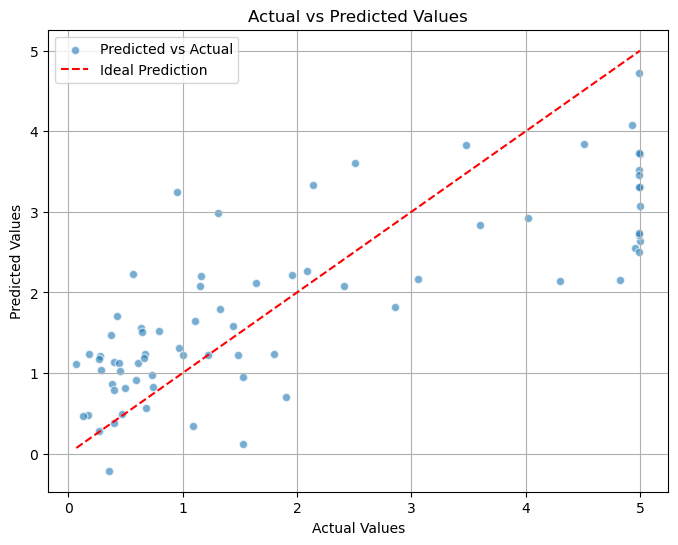

In [422]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize KFold
kf = KFold(n_splits=5, shuffle=False)  # 5-fold cross-validation

# Lists to store the performance metrics across folds
mse_scores = []
mae_scores = []
r2_scores = []

# Lists to store actual and predicted values for plotting
actual_values = []
predicted_values = []

# Define the hyperparameters for SVR
svr_params = {'C': 1, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}

# K-fold cross-validation
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and test sets
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Initialize the SVR model with the specified hyperparameters
    svr_model = SVR(**svr_params)

    # Fit the model on the training data
    svr_model.fit(X_train, y_train)

    # Make predictions using the model
    y_pred = svr_model.predict(X_test)

    # Store actual and predicted values for plotting
    actual_values.extend(y_test)
    predicted_values.extend(y_pred)

    # Calculate performance metrics
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store the metrics for this fold
    mse_scores.append(mse)
    mae_scores.append(mae)
    r2_scores.append(r2)

# Calculate and print average scores
print(f'Average MSE: {np.mean(mse_scores):.4f}')
print(f'Average MAE: {np.mean(mae_scores):.4f}')
print(f'Average R-squared: {np.mean(r2_scores):.4f}')

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(actual_values, predicted_values, alpha=0.6, edgecolors='w', label='Predicted vs Actual')
plt.plot([min(actual_values), max(actual_values)], [min(actual_values), max(actual_values)],
         color='red', linestyle='--', label='Ideal Prediction')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.grid(True)
plt.show()

# Random Forest

In [309]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Split the data into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=20)

# Initialize the RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42 , max_depth=1)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Calculate and print performance metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error (MSE): {mse:.4f}')
print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'R-squared: {r2:.4f}')


Mean Squared Error (MSE): 2.4285
Mean Absolute Error (MAE): 1.0683
R-squared: 0.0730


# Gradient Boosting

In [423]:
from sklearn.ensemble import GradientBoostingRegressor

# K-fold cross-validation
kf = KFold(n_splits=5, shuffle=False)

# Lists to store the performance metrics
mse_scores = []
mae_scores = []
r2_scores = []

# Define the parameter grid for GradientBoostingRegressor
param_grid = {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 0.2], 'max_depth': [3, 5, 7]}

# K-fold cross-validation
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and test sets
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]


    # Initialize GridSearchCV with GradientBoostingRegressor
    grid_search = GridSearchCV(GradientBoostingRegressor(), param_grid, cv=5, scoring='neg_mean_squared_error')

    # Fit the model
    grid_search.fit(X_train, y_train)

    # Get the best model from the grid search
    best_model = grid_search.best_estimator_

    # Make predictions and evaluate
    y_pred = best_model.predict(X_test)
    mse_scores.append(mean_squared_error(y_test, y_pred))
    mae_scores.append(mean_absolute_error(y_test, y_pred))
    r2_scores.append(r2_score(y_test, y_pred))

# Average performance metrics
print(f'  Best parameters: {grid_search.best_params_}')
print(f'Average MSE: {np.mean(mse_scores):.4f}')
print(f'Average MAE: {np.mean(mae_scores):.4f}')
print(f'Average R-squared: {np.mean(r2_scores):.4f}')


  Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Average MSE: 1.4342
Average MAE: 0.8440
Average R-squared: 0.4145


#  K-Nearest Neighbors (KNN) Regressor

In [424]:
from sklearn.neighbors import KNeighborsRegressor

# K-fold cross-validation
kf = KFold(n_splits=5, shuffle=False)

# Lists to store the performance metrics
mse_scores = []
mae_scores = []
r2_scores = []

# Define the parameter grid for KNeighborsRegressor
param_grid = {'n_neighbors': [3, 5, 7, 10], 'weights': ['uniform', 'distance']}

# K-fold cross-validation
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and test sets
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Initialize GridSearchCV with KNeighborsRegressor
    grid_search = GridSearchCV(KNeighborsRegressor(), param_grid, cv=5, scoring='neg_mean_squared_error')

    # Fit the model
    grid_search.fit(X_train, y_train)

    # Get the best model from the grid search
    best_model = grid_search.best_estimator_

    # Make predictions and evaluate
    y_pred = best_model.predict(X_test)
    mse_scores.append(mean_squared_error(y_test, y_pred))
    mae_scores.append(mean_absolute_error(y_test, y_pred))
    r2_scores.append(r2_score(y_test, y_pred))

# Average performance metrics
print(f'Average MSE: {np.mean(mse_scores):.4f}')
print(f'Average MAE: {np.mean(mae_scores):.4f}')
print(f'Average R-squared: {np.mean(r2_scores):.4f}')


Average MSE: 1.2880
Average MAE: 0.9094
Average R-squared: 0.4664


# Linear Regression

In [425]:
from sklearn.linear_model import LinearRegression

# K-fold cross-validation
kf = KFold(n_splits=5, shuffle=False)

# Lists to store the performance metrics
mse_scores = []
mae_scores = []
r2_scores = []

# Initialize the Linear Regression model
lr_model = LinearRegression()

# K-fold cross-validation
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and test sets
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Fit the model
    lr_model.fit(X_train, y_train)

    # Make predictions and evaluate
    y_pred = lr_model.predict(X_test)
    mse_scores.append(mean_squared_error(y_test, y_pred))
    mae_scores.append(mean_absolute_error(y_test, y_pred))
    r2_scores.append(r2_score(y_test, y_pred))

# Average performance metrics
print(f'Average MSE: {np.mean(mse_scores):.4f}')
print(f'Average MAE: {np.mean(mae_scores):.4f}')
print(f'Average R-squared: {np.mean(r2_scores):.4f}')


Average MSE: 2.6357
Average MAE: 1.2069
Average R-squared: 0.0255


# 5. Neural Networks (MLPRegressor)


In [426]:
from sklearn.neural_network import MLPRegressor

# K-fold cross-validation
kf = KFold(n_splits=5, shuffle=False)

# Lists to store the performance metrics
mse_scores = []
mae_scores = []
r2_scores = []

# Define the parameter grid for MLPRegressor
param_grid = {'hidden_layer_sizes': [(50,), (100,)], 'activation': ['relu', 'tanh']}

# K-fold cross-validation
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and test sets
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Initialize GridSearchCV with MLPRegressor
    grid_search = GridSearchCV(MLPRegressor(max_iter=3000), param_grid, cv=5, scoring='neg_mean_squared_error')

    # Fit the model
    grid_search.fit(X_train, y_train)

    # Get the best model from the grid search
    best_model = grid_search.best_estimator_

    # Make predictions and evaluate
    y_pred = best_model.predict(X_test)
    mse_scores.append(mean_squared_error(y_test, y_pred))
    mae_scores.append(mean_absolute_error(y_test, y_pred))
    r2_scores.append(r2_score(y_test, y_pred))

# Average performance metrics
print(f'Average MSE: {np.mean(mse_scores):.4f}')
print(f'Average MAE: {np.mean(mae_scores):.4f}')
print(f'Average R-squared: {np.mean(r2_scores):.4f}')


Average MSE: 1.9288
Average MAE: 1.1396
Average R-squared: 0.2809
